1. Import Library

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', rc={'grid.linestyle': '--', 'figure.figsize': (10, 5)})

2. Baca Dataset

In [15]:
from google.colab import files
uploaded = files.upload()

df = pd.read_excel(list(uploaded.keys())[0])
df.head()

Saving day.xlsx to day (1).xlsx


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


3. Cek dan Bersihkan Data

In [16]:
# Konstanta label (dipakai berulang di grafik)
MUSIM  = {1: 'Musim Dingin', 2: 'Musim Semi', 3: 'Musim Panas', 4: 'Musim Gugur'}
CUACA  = {1: 'Cerah', 2: 'Berkabut/Mendung', 3: 'Hujan/Salju Ringan', 4: 'Hujan Lebat'}
HARI   = {0: 'Min', 1: 'Sen', 2: 'Sel', 3: 'Rab', 4: 'Kam', 5: 'Jum', 6: 'Sab'}
JENIS  = {0: 'Libur/Akhir Pekan', 1: 'Hari Kerja'}
BULAN  = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

# Pembersihan: hapus data kosong & pastikan tipe data benar
df = df.dropna().copy()
df['dteday'] = pd.to_datetime(df['dteday'], errors='coerce')
df['cnt']    = pd.to_numeric(df['cnt'], errors='coerce')
df = df.dropna(subset=['dteday', 'cnt']).sort_values('dteday')

# Kolom turunan: label kategori & satuan asli (suhu/kelembapan/angin di dataset ternormalisasi)
df = df.assign(
    month         = df['dteday'].dt.to_period('M').dt.to_timestamp(),   # awal bulan, mis. 2011-01-01
    year          = df['dteday'].dt.year,
    season_label  = df['season'].map(MUSIM),
    weather_label = df['weathersit'].map(CUACA),
    weekday_label = df['weekday'].map(HARI),
    hari_kerja    = df['workingday'].map(JENIS),
    temp_c        = df['temp'] * 47 - 8,       # derajat Celsius
    hum_pct       = df['hum'] * 100,           # persen
    wind_kmh      = df['windspeed'] * 67,      # km/jam
)

# Kategori: kolom -> (nama tampilan, urutan nilai)
KATEGORI = {
    'season_label':  ('Musim',         list(MUSIM.values())),
    'weather_label': ('Kondisi Cuaca', [c for c in CUACA.values() if c in set(df['weather_label'])]),
    'weekday_label': ('Hari',          list(HARI.values())),
    'hari_kerja':    ('Jenis Hari',    ['Hari Kerja', 'Libur/Akhir Pekan']),
}

# Variabel numerik: kolom -> label sumbu
FAKTOR_CUACA   = {'temp_c': 'Suhu (°C)', 'hum_pct': 'Kelembapan (%)', 'wind_kmh': 'Kecepatan Angin (km/jam)'}
LABEL_NUMERIK  = {'cnt': 'Jumlah Penyewaan Harian', **FAKTOR_CUACA}

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   instant        731 non-null    int64         
 1   dteday         731 non-null    datetime64[ns]
 2   season         731 non-null    int64         
 3   yr             731 non-null    int64         
 4   mnth           731 non-null    int64         
 5   holiday        731 non-null    int64         
 6   weekday        731 non-null    int64         
 7   workingday     731 non-null    int64         
 8   weathersit     731 non-null    int64         
 9   temp           731 non-null    float64       
 10  atemp          731 non-null    float64       
 11  hum            731 non-null    float64       
 12  windspeed      731 non-null    float64       
 13  casual         731 non-null    int64         
 14  registered     731 non-null    int64         
 15  cnt            731 non-

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,...,cnt,month,year,season_label,weather_label,weekday_label,hari_kerja,temp_c,hum_pct,wind_kmh
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,...,985,2011-01-01,2011,Musim Dingin,Berkabut/Mendung,Sab,Libur/Akhir Pekan,8.175849,80.5833,10.749882
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,...,801,2011-01-01,2011,Musim Dingin,Berkabut/Mendung,Min,Libur/Akhir Pekan,9.083466,69.6087,16.652113
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,...,1349,2011-01-01,2011,Musim Dingin,Cerah,Sen,Hari Kerja,1.229108,43.7273,16.636703
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,...,1562,2011-01-01,2011,Musim Dingin,Cerah,Sel,Hari Kerja,1.400000,59.0435,10.739832
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,...,1600,2011-01-01,2011,Musim Dingin,Cerah,Rab,Hari Kerja,2.666979,43.6957,12.522300


4. Agregasi Data Berdasarkan Bulan

In [17]:
monthly_volume = df.groupby('month', as_index=False)['cnt'].sum().rename(columns={'cnt': 'total'})
monthly_volume.head()

,month,total
0,2011-01-01,38189
1,2011-02-01,48215
2,2011-03-01,64045
3,2011-04-01,94870
4,2011-05-01,135821


5. Line Chart dan Bar Chart - Tren Penyewaan per Bulan

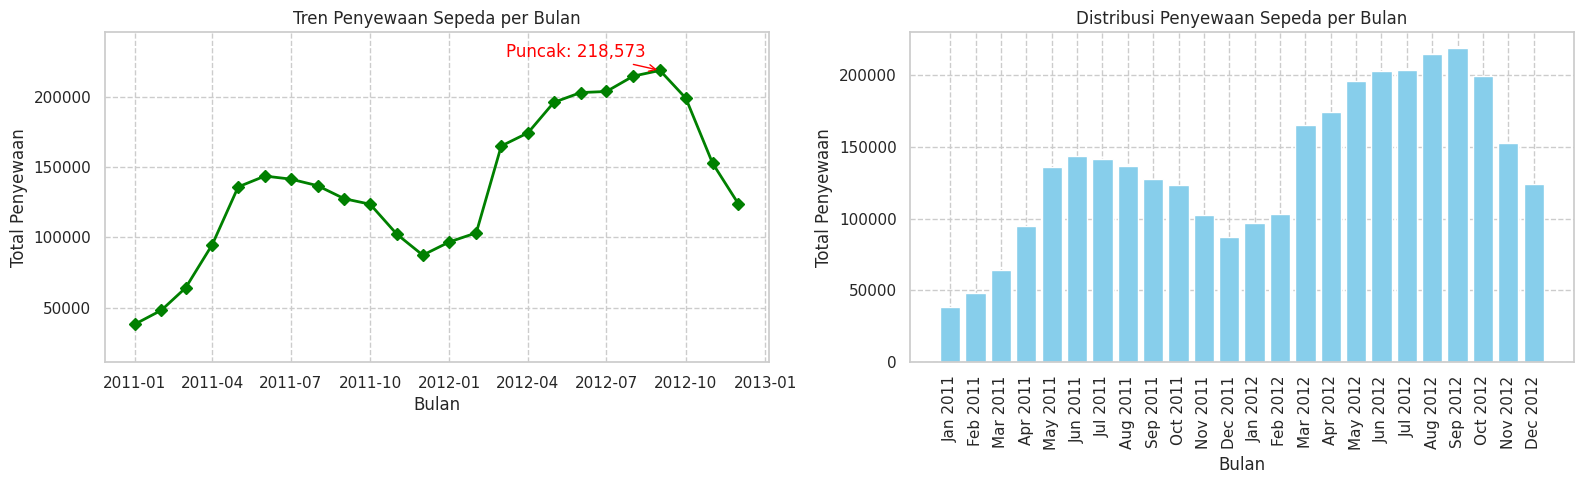

In [18]:
fig, (ax_line, ax_bar) = plt.subplots(1, 2, figsize=(16, 5))

# Line chart + anotasi titik tertinggi
puncak = monthly_volume.loc[monthly_volume['total'].idxmax()]
ax_line.plot(monthly_volume['month'], monthly_volume['total'], color='green', marker='D', linewidth=2)
ax_line.annotate(f"Puncak: {puncak['total']:,.0f}", xy=(puncak['month'], puncak['total']),
                 xytext=(-10, 10), textcoords='offset points', ha='right', color='red',
                 arrowprops=dict(arrowstyle='->', color='red'))
ax_line.margins(y=0.15)   # beri ruang di atas untuk anotasi
ax_line.set(title='Tren Penyewaan Sepeda per Bulan', xlabel='Bulan', ylabel='Total Penyewaan')

# Bar chart
ax_bar.bar(monthly_volume['month'].dt.strftime('%b %Y'), monthly_volume['total'], color='skyblue')
ax_bar.tick_params(axis='x', rotation=90)
ax_bar.set(title='Distribusi Penyewaan Sepeda per Bulan', xlabel='Bulan', ylabel='Total Penyewaan')

plt.tight_layout()
plt.show()

6. Histogram - Distribusi Variabel Numerik

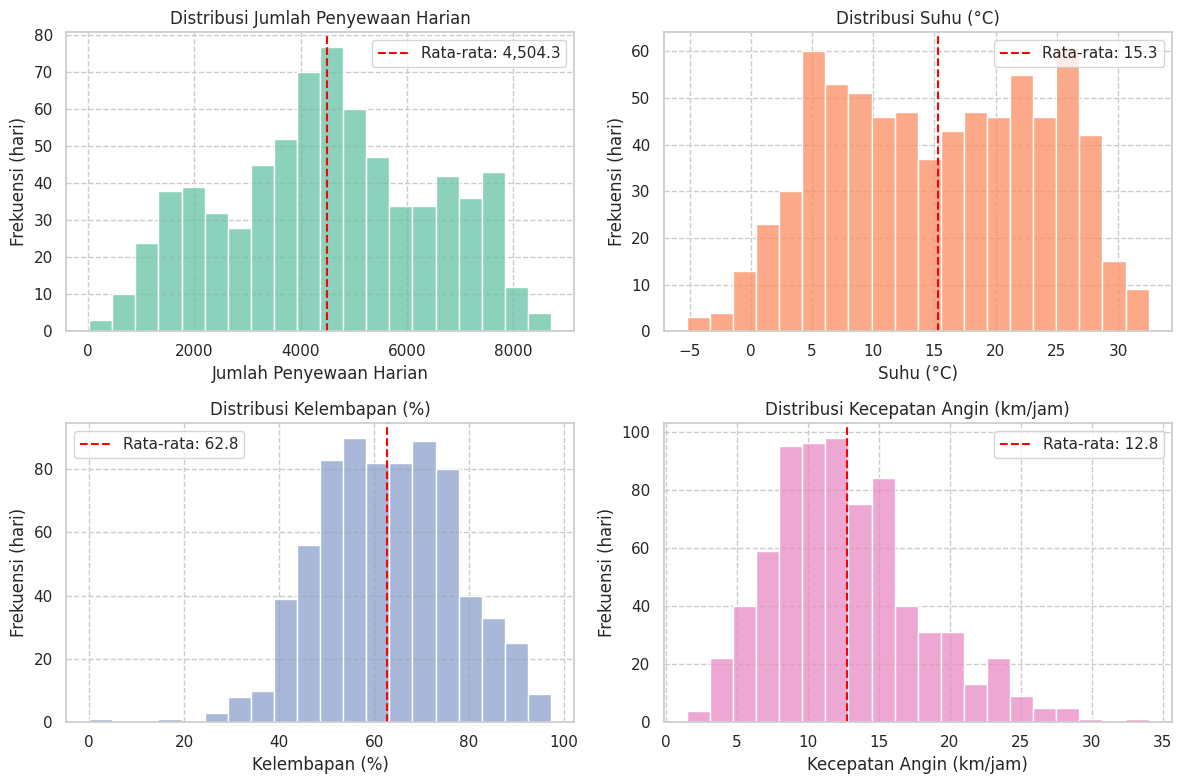

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (kolom, label), warna in zip(axes.flat, LABEL_NUMERIK.items(), sns.color_palette('Set2')):
    rata2 = df[kolom].mean()
    sns.histplot(df[kolom], bins=20, color=warna, ax=ax)
    ax.axvline(rata2, color='red', linestyle='--', label=f'Rata-rata: {rata2:,.1f}')
    ax.set(title=f'Distribusi {label}', xlabel=label, ylabel='Frekuensi (hari)')
    ax.legend()

plt.tight_layout()
plt.show()

7. Bar Chart - Rata-rata Penyewaan per Kategori

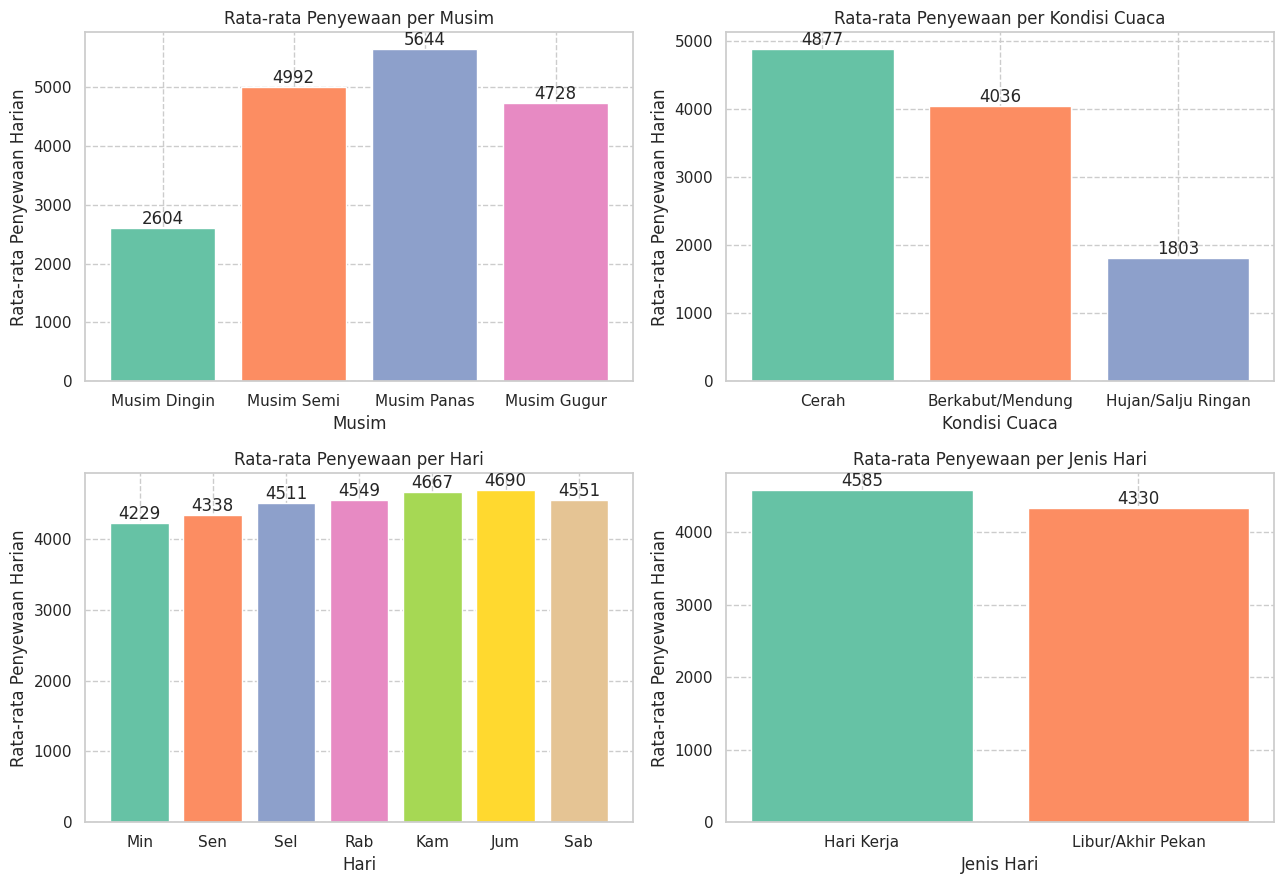

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (kolom, (nama, urutan)) in zip(axes.flat, KATEGORI.items()):
    rata2 = df.groupby(kolom)['cnt'].mean().reindex(urutan)
    ax.bar_label(ax.bar(rata2.index, rata2.values, color=sns.color_palette('Set2', len(urutan))), fmt='%.0f')
    ax.set(title=f'Rata-rata Penyewaan per {nama}', xlabel=nama, ylabel='Rata-rata Penyewaan Harian')

plt.tight_layout()
plt.show()

8. Boxplot - Sebaran Penyewaan per Kategori

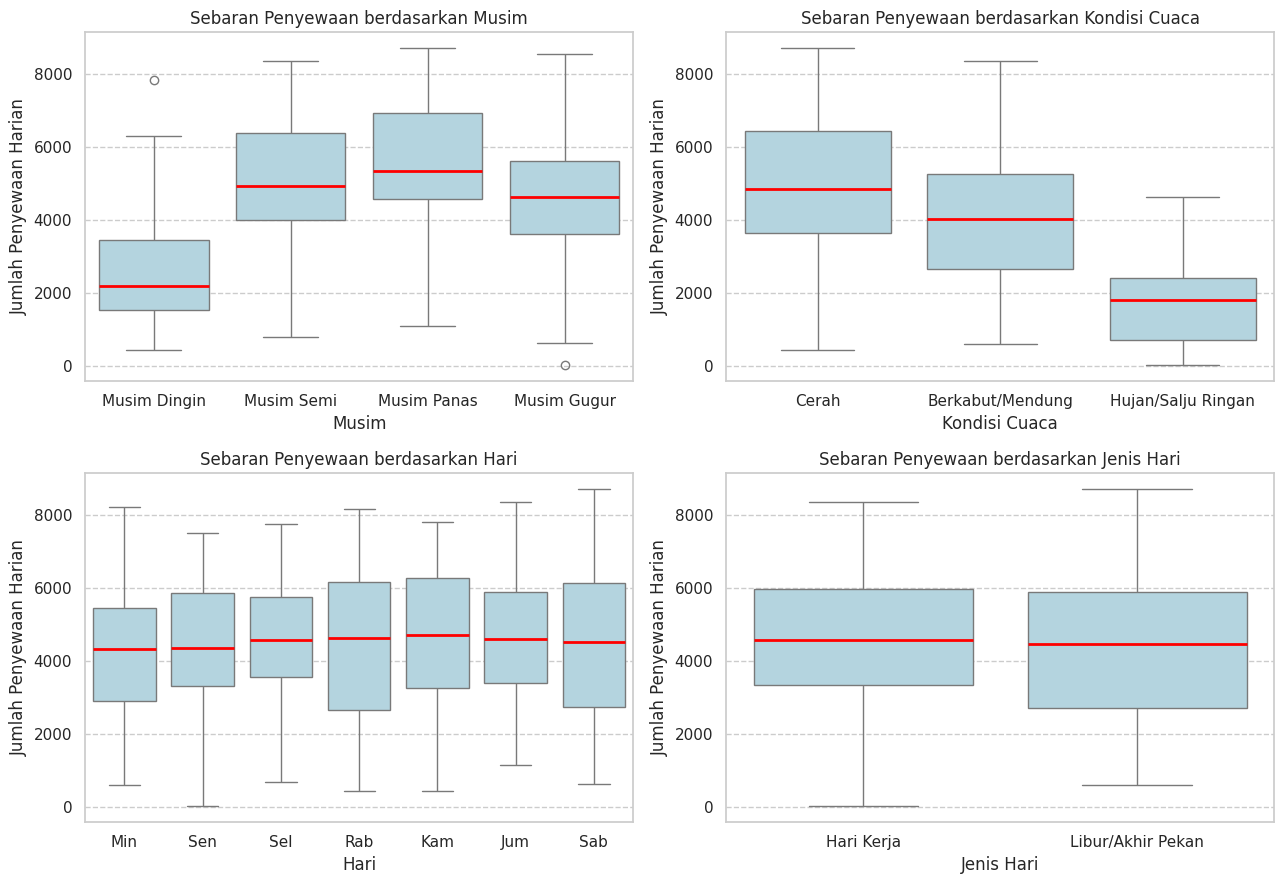

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (kolom, (nama, urutan)) in zip(axes.flat, KATEGORI.items()):
    sns.boxplot(data=df, x=kolom, y='cnt', order=urutan, color='lightblue',
                medianprops={'color': 'red', 'linewidth': 2}, ax=ax)
    ax.set(title=f'Sebaran Penyewaan berdasarkan {nama}', xlabel=nama, ylabel='Jumlah Penyewaan Harian')

plt.tight_layout()
plt.show()

9. Scatter Plot - Hubungan Cuaca dengan Jumlah Penyewaan

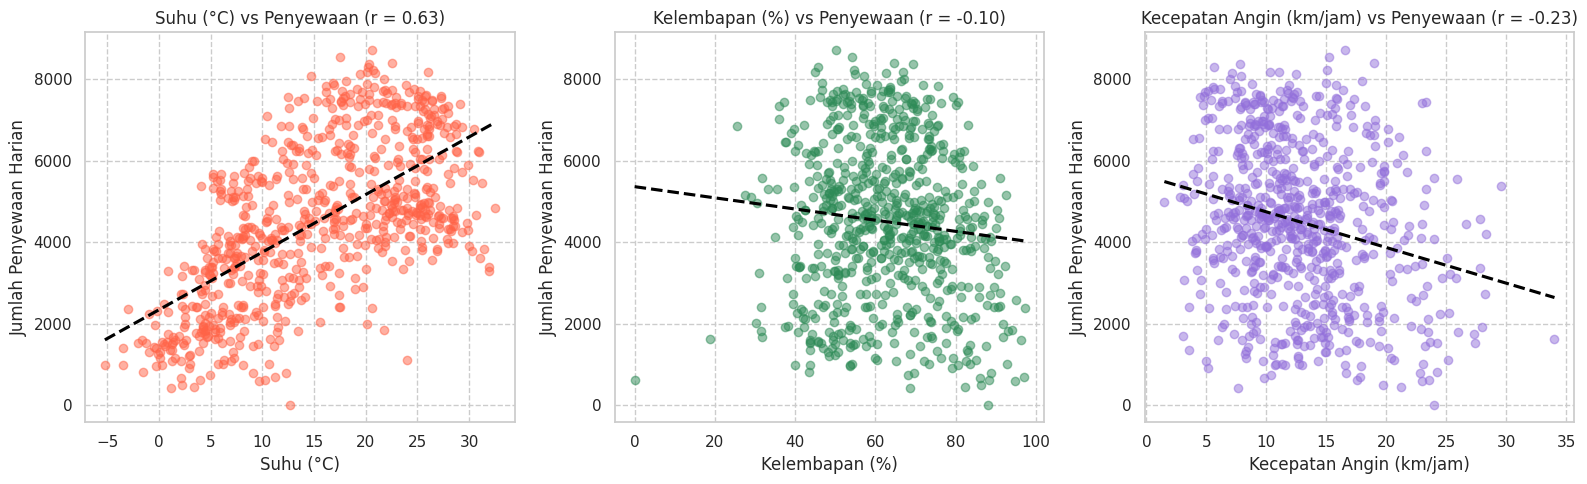

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (kolom, label), warna in zip(axes, FAKTOR_CUACA.items(), ['tomato', 'seagreen', 'mediumpurple']):
    sns.regplot(data=df, x=kolom, y='cnt', ci=None, color=warna,
                scatter_kws={'alpha': 0.5}, line_kws={'color': 'black', 'linestyle': '--'}, ax=ax)
    ax.set(title=f'{label} vs Penyewaan (r = {df[kolom].corr(df["cnt"]):.2f})',
           xlabel=label, ylabel='Jumlah Penyewaan Harian')

plt.tight_layout()
plt.show()

10. Line Chart - Pengguna Casual vs Registered dan Perbandingan 2011 vs 2012

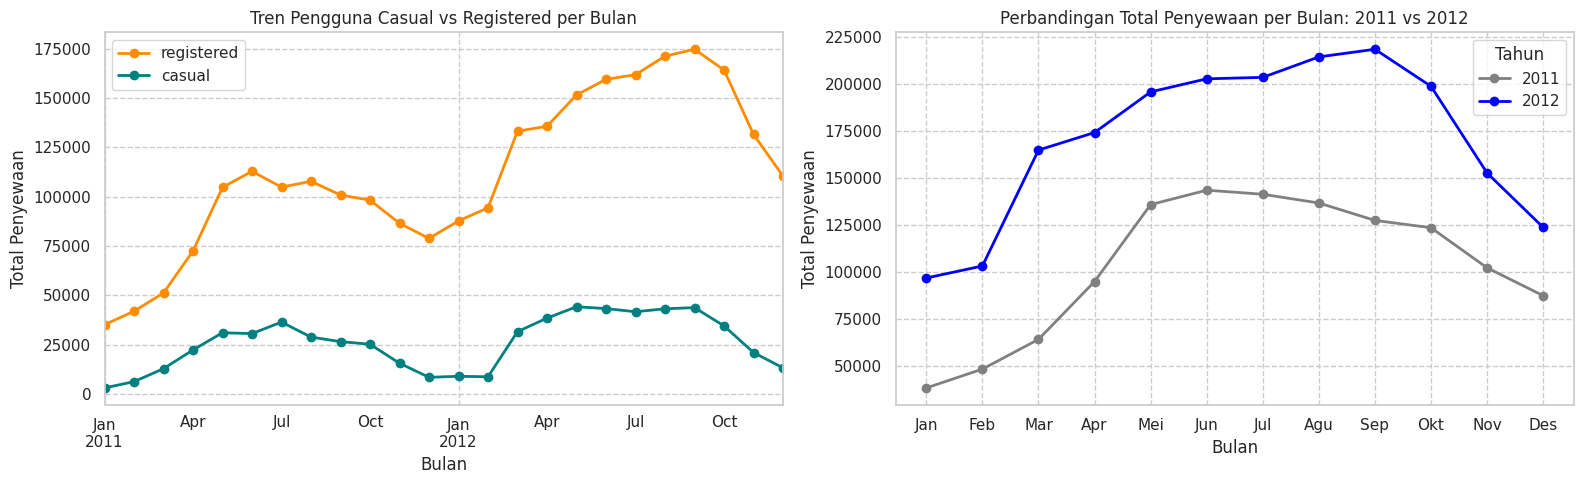

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# (a) Casual vs Registered per bulan
df.groupby('month')[['registered', 'casual']].sum().plot(ax=ax1, marker='o', linewidth=2, color=['darkorange', 'teal'])
ax1.set(title='Tren Pengguna Casual vs Registered per Bulan', xlabel='Bulan', ylabel='Total Penyewaan')

# (b) Total penyewaan per bulan: 2011 vs 2012
df.pivot_table(index='mnth', columns='year', values='cnt', aggfunc='sum').plot(ax=ax2, marker='o', linewidth=2, color=['gray', 'blue'])
ax2.set_xticks(range(1, 13), BULAN)
ax2.set(title='Perbandingan Total Penyewaan per Bulan: 2011 vs 2012', xlabel='Bulan', ylabel='Total Penyewaan')
ax2.legend(title='Tahun')

plt.tight_layout()
plt.show()

11. Heatmap - Korelasi Antar Variabel dan Pola Bulan × Hari

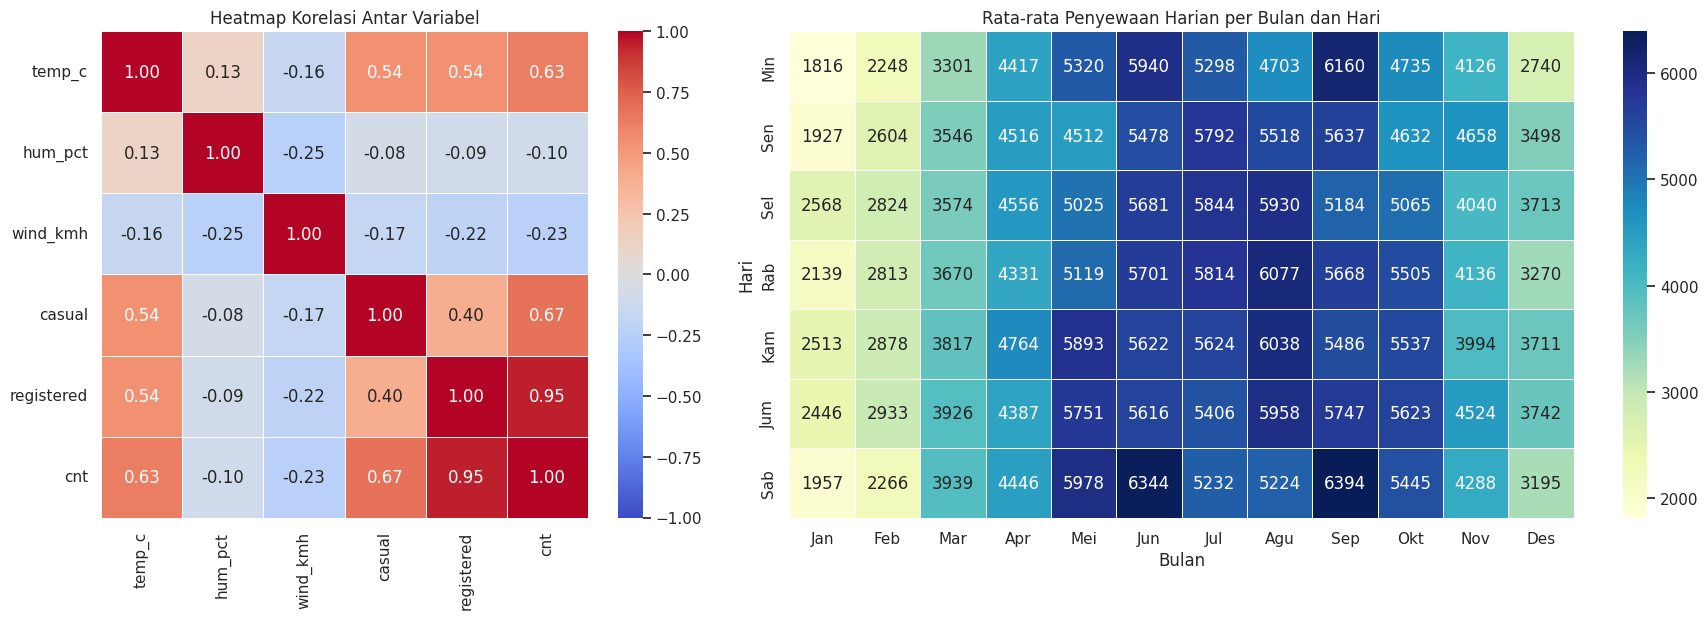

In [25]:
korelasi = df[['temp_c', 'hum_pct', 'wind_kmh', 'casual', 'registered', 'cnt']].corr()
pola     = (df.pivot_table(index='weekday_label', columns='mnth', values='cnt', aggfunc='mean')
             .reindex(KATEGORI['weekday_label'][1]).set_axis(BULAN, axis=1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1, 1.6]})

sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax1)
ax1.set(title='Heatmap Korelasi Antar Variabel')

sns.heatmap(pola, annot=True, fmt='.0f', cmap='YlGnBu', linewidths=0.5, ax=ax2)
ax2.set(title='Rata-rata Penyewaan Harian per Bulan dan Hari', xlabel='Bulan', ylabel='Hari')

plt.tight_layout()
plt.show()

12. Pie Chart - Proporsi Pengguna Casual vs Registered

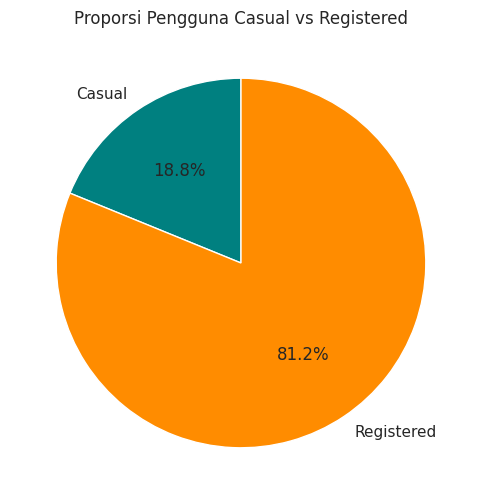

In [24]:
total_pengguna = df[['casual', 'registered']].sum()

plt.figure(figsize=(6, 6))
plt.pie(total_pengguna, labels=total_pengguna.index.str.capitalize(), autopct='%1.1f%%',
        colors=['teal', 'darkorange'], startangle=90, wedgeprops={'edgecolor': 'white'})
plt.title('Proporsi Pengguna Casual vs Registered')
plt.show()